# 04 · Machine-learning regression imputers
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mvya0005/mma3001-project-sensor-reconstruction/blob/main/notebooks/04_machine_learning_regression.ipynb)

Each model learns a **correction** to the robust linear baseline from *gap-aware* features: position in the gap, gap length, change across the gap, time of day, weekday, the training typical-day profile, yesterday's and tomorrow's shape over the same hours, and (optionally) the building occupancy proxy. See `sensorfill/features.py` for the full feature table.

Training examples are made by hiding observed training values (self-supervision). All model selection uses **grouped K-fold cross-validation** on the training period: the rows of one gap stay in one fold, because they are highly correlated and splitting them would leak information. The validation period is then used once per model family, to compare families.

| Unit topic | Where |
|---|---|
| 5.1 Linear regression | OLS and ridge on standardised features |
| 5.2 Decision tree regression | CART; depth-controlled over/under-fitting curve |
| 5.3 Support vector regression | ε-SVR with an RBF kernel (trained on a gap-grouped subsample: O(n²) memory) |
| 5.4 Neural network regression | MLP with early stopping |
| 5.5 Evaluating regression performance | RMSE/MAE/bias on hidden points, per gap length |
| 5.6 Training data evaluation and selection | grouped CV, learning curve over training-set size, occupancy ablation |
| 3.6 Interpolation in ML | the models are *local interpolators* corrected by learned context |

In [1]:
# ---- Environment setup: works on Google Colab and locally ----
import os, sys, subprocess
from pathlib import Path

GITHUB_REPO = "mvya0005/mma3001-project-sensor-reconstruction"  # owner/name of this repository
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo_dir = Path("/content") / GITHUB_REPO.split("/")[1]
    if not repo_dir.exists():
        subprocess.run(["git", "clone", "-q", f"https://github.com/{GITHUB_REPO}.git", str(repo_dir)], check=True)
    os.chdir(repo_dir)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
    sys.path.insert(0, str(repo_dir / "src"))  # editable install is not visible until restart
    from google.colab import drive
    drive.mount("/content/drive")
    RAW = Path("/content/drive/MyDrive/MMA3001/raw")              # put the two Moodle zip files here
    PROCESSED = Path("/content/drive/MyDrive/MMA3001/processed")  # cached across Colab sessions
else:
    if Path.cwd().name == "notebooks":
        os.chdir("..")
    sys.path.insert(0, str(Path("src").resolve()))
    RAW, PROCESSED = Path("data/raw"), Path("data/processed")

PROCESSED.mkdir(parents=True, exist_ok=True)
if not (PROCESSED / "audit.json").exists():
    subprocess.run([sys.executable, "scripts/preprocess.py", "--raw", str(RAW), "--out", str(PROCESSED)], check=True)
print("repository:", Path.cwd(), "| processed data:", PROCESSED)

repository: /home/claude/mma3001-sensor-reconstruction | processed data: data/processed


In [2]:
import json, time, warnings
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold, cross_validate
from sensorfill import benchmark as bm, features as ft, interpolation as itp, ml, study, plotting
from sensorfill.plotting import plt
plotting.setup()
# MLP grid points that stop at max_iter emit ConvergenceWarnings; early stopping on a held-out
# 10 % already guards against overfitting, so the warnings are silenced to keep the output readable.
warnings.filterwarnings("ignore", message="Stochastic Optimizer")
s = study.load_study(PROCESSED, "co2")
y_tr, ts_tr, occ_tr = s.part("train"); y_v, ts_v, occ_v = s.part("val")

def builder(ts, occ, use_occ=True):
    return ft.GapFeatureBuilder(ts, occ if use_occ else None, s.profile_values(ts), level_ref=s.level_ref)

X, r, g = ft.make_training_set(y_tr, builder(ts_tr, occ_tr), gap_lengths=study.GAP_LENGTHS, rng=0)
print(f"training rows: {len(X):,} from {len(np.unique(g)):,} artificial gaps; target (residual) std = {r.std():.1f} ppm")
X.describe().T[["mean", "std", "min", "max"]].round(2)

training rows: 17,967 from 955 artificial gaps; target (residual) std = 28.6 ppm


,mean,std,min,max
delta,1.98,40.58,-134.00,147.33
level,10.71,30.44,-38.50,136.00
pos,0.50,0.28,0.01,0.99
gap_len,3.82,0.99,0.69,4.98
dist,2.42,1.00,0.69,4.29
tod_sin,0.00,0.70,-1.00,1.00
tod_cos,0.00,0.71,-1.00,1.00
dow_sin,-0.05,0.68,-0.97,0.97
dow_cos,0.00,0.73,-0.90,1.00
weekend,0.29,0.46,0.00,1.00


## 1. Over- and under-fitting: tree depth
A decision tree's depth is a direct complexity knob. The training error falls monotonically with depth. The cross-validated error is U-shaped: shallow trees under-fit and deep trees memorise individual gaps.

,depth,train RMSE,CV RMSE
0,1,24.87,25.15
1,2,22.00,22.79
2,4,19.17,21.60
3,6,17.35,21.26
4,8,15.38,22.40
5,12,11.12,23.51
6,16,7.25,24.51
7,24,2.33,26.03
8,unlimited,0.00,25.92


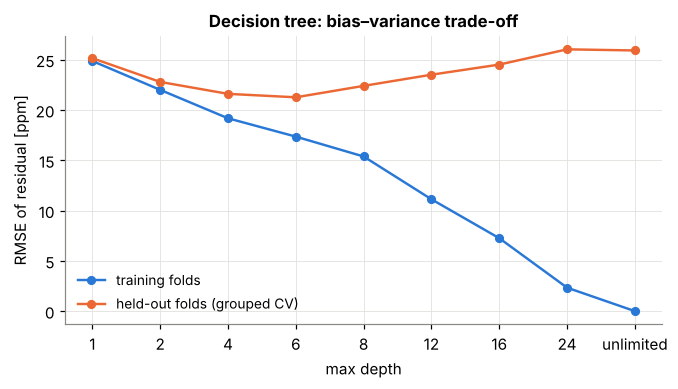

In [3]:
cv = GroupKFold(n_splits=4)
rows = []
for d in (1, 2, 4, 6, 8, 12, 16, 24, None):
    out = cross_validate(ml.make_model("tree", max_depth=d, min_samples_leaf=1), X, r, groups=g, cv=cv,
                         scoring="neg_root_mean_squared_error", return_train_score=True)
    rows.append({"depth": d or "unlimited", "train RMSE": -out["train_score"].mean(), "CV RMSE": -out["test_score"].mean()})
depth = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7, 3.4))
xx = np.arange(len(depth))
ax.plot(xx, depth["train RMSE"], marker="o", color=plotting.PALETTE[0], label="training folds")
ax.plot(xx, depth["CV RMSE"], marker="o", color=plotting.PALETTE[1], label="held-out folds (grouped CV)")
ax.set_xticks(xx, depth["depth"].astype(str)); ax.set_xlabel("max depth"); ax.set_ylabel("RMSE of residual [ppm]"); ax.legend()
ax.set_title("Decision tree: bias–variance trade-off")
_ = plotting.save(fig, "04_tree_depth")
depth.round(2)

## 2. Hyperparameter tuning of every model family (grouped 4-fold CV on training data)

In [4]:
grids = dict(ml.PARAM_GRIDS)
grids["mlp"] = {"reg__hidden_layer_sizes": [(32,), (64, 64)], "reg__alpha": [1e-4, 1e-2]}   # keep CPU time reasonable
caps = {"svr": 6000, "mlp": 20000}   # SVR kernel matrix is O(n²) in memory/time
tuned, rows = {}, []
for name in ("linear", "ridge", "tree", "forest", "svr", "mlp"):
    t0 = time.perf_counter()
    gs = ml.tune(name, X, r, g, n_splits=4, max_rows=caps.get(name), grid=grids[name])
    tuned[name] = gs
    i = gs.best_index_
    rows.append({"model": name, "CV RMSE": -gs.best_score_, "train RMSE": -gs.cv_results_["mean_train_score"][i],
                 "best params": {k.replace("reg__", ""): v for k, v in gs.best_params_.items()},
                 "tuning time [s]": time.perf_counter() - t0})
cv_tab = pd.DataFrame(rows).set_index("model"); cv_tab.round(2)

,CV RMSE,train RMSE,best params,tuning time [s]
model,,,,
linear,20.54,19.88,{'fit_intercept': True},1.84
ridge,20.54,19.88,{'alpha': 100},0.32
tree,20.97,17.85,"{'max_depth': 6, 'min_samples_leaf': 50}",2.01
forest,18.92,5.23,"{'max_depth': None, 'min_samples_leaf': 2}",159.81
svr,22.88,13.74,"{'C': 10, 'epsilon': 0.5, 'gamma': 0.05}",39.03
mlp,20.75,14.27,"{'alpha': 0.01, 'hidden_layer_sizes': (32,)}",83.28


In [5]:
best_params = {k: {p.replace("reg__", ""): (list(v) if isinstance(v, tuple) else v) for p, v in gs.best_params_.items()} for k, gs in tuned.items()}
Path("reports").mkdir(exist_ok=True)
Path("reports/ml_best_params.json").write_text(json.dumps(best_params, indent=1, default=str))
best_params

{'linear': {'fit_intercept': True},
 'ridge': {'alpha': 100},
 'tree': {'max_depth': 6, 'min_samples_leaf': 50},
 'forest': {'max_depth': None, 'min_samples_leaf': 2},
 'svr': {'C': 10, 'epsilon': 0.5, 'gamma': 0.05},
 'mlp': {'alpha': 0.01, 'hidden_layer_sizes': [32]}}

## 3. How much training data is needed? (learning curve)
The training period is truncated to its first 1, 2, 4, 6 and 8.7 weeks. A random forest and ridge regression are refit on each, and the validation RMSE on 12-hour gaps is recorded.

model,forest,ridge
weeks,,
1.0,32.30,26.60
2.0,25.05,37.87
4.0,23.96,22.47
6.0,23.38,21.41
8.7,20.50,21.49


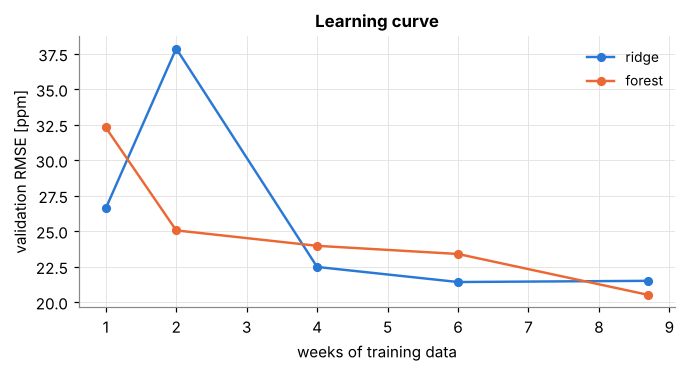

In [6]:
rows = []
for weeks in (1, 2, 4, 6, 8.7):
    n = int(weeks * 7 * 144)
    Xs, rs, gs_ = ft.make_training_set(y_tr[:n], builder(ts_tr[:n], occ_tr[:n]), gap_lengths=study.GAP_LENGTHS, rng=0)
    for name in ("ridge", "forest"):
        model = ml.make_model(name, **{k: v for k, v in best_params[name].items()})
        imp = ml.MLImputer(model, builder(ts_v, occ_v)).fit(Xs, rs)
        res = bm.run_benchmark(y_v, bm.Context(ts=ts_v), {name: lambda y, c, imp=imp: imp.impute(y)}, gap_lengths=(36, 72), repeats=2, seed=11)
        rows.append({"weeks": weeks, "model": name, "rows": len(Xs), "val RMSE (6-12 h gaps)": res.rmse.mean()})
lc = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7, 3.2))
for i, name in enumerate(("ridge", "forest")):
    d = lc[lc.model == name]; ax.plot(d.weeks, d["val RMSE (6-12 h gaps)"], marker="o", color=plotting.PALETTE[i], label=name)
ax.set_xlabel("weeks of training data"); ax.set_ylabel("validation RMSE [ppm]"); ax.legend(); ax.set_title("Learning curve")
_ = plotting.save(fig, "04_learning_curve")
lc.pivot(index="weeks", columns="model", values="val RMSE (6-12 h gaps)").round(2)

## 4. Validation comparison and the occupancy ablation

In [7]:
methods = {"Linear": lambda y, c: itp.fill_linear(y),
           "Daily profile + offset": lambda y, c: itp.fill_profile(y, c.ts, profile=s.train_profile)}
fit_times = {}
for use_occ in (False, True):
    Xo, ro, go = (X, r, g) if use_occ else ft.make_training_set(y_tr, builder(ts_tr, occ_tr, False), gap_lengths=study.GAP_LENGTHS, rng=0)
    for name in ("linear", "ridge", "tree", "forest", "svr", "mlp"):
        Xf, rf, _ = ml.subsample(Xo, ro, go, caps.get(name))
        imp = ml.MLImputer(ml.make_model(name, **best_params[name]), builder(ts_v, occ_v, use_occ)).fit(Xf, rf)
        label = f"{name}{' +occ' if use_occ else ''}"
        fit_times[label] = imp.fit_seconds
        methods[label] = lambda y, c, imp=imp: imp.impute(y)
val_res = bm.run_benchmark(y_v, bm.Context(ts=ts_v), methods, repeats=3, seed=12)
val_res.to_csv("reports/val_ml.csv", index=False)
tab = bm.summarise(val_res).round(1)
tab["fit time [s]"] = pd.Series(fit_times).round(2)
tab

gap_len,1,3,6,18,36,72,144,fit time [s]
method,,,,,,,,
linear +occ,12.2,13.3,14.3,15.1,20.1,21.1,30.6,0.02
ridge +occ,12.2,13.3,14.2,15.1,20.1,21.1,30.7,0.02
forest +occ,11.5,11.4,12.5,14.4,19.9,21.8,30.9,7.86
mlp +occ,13.5,12.8,15.1,15.9,21.5,21.2,31.4,22.44
linear,11.8,12.8,13.8,15.3,20.3,21.4,31.6,0.03
ridge,11.8,12.8,13.8,15.3,20.3,21.4,31.6,0.03
Daily profile + offset,11.3,12.5,13.2,15.5,19.2,21.0,31.7,NaN
forest,11.8,11.3,12.0,14.5,19.3,22.4,32.4,7.16
tree,12.3,11.9,13.6,15.0,21.0,24.3,33.2,0.08


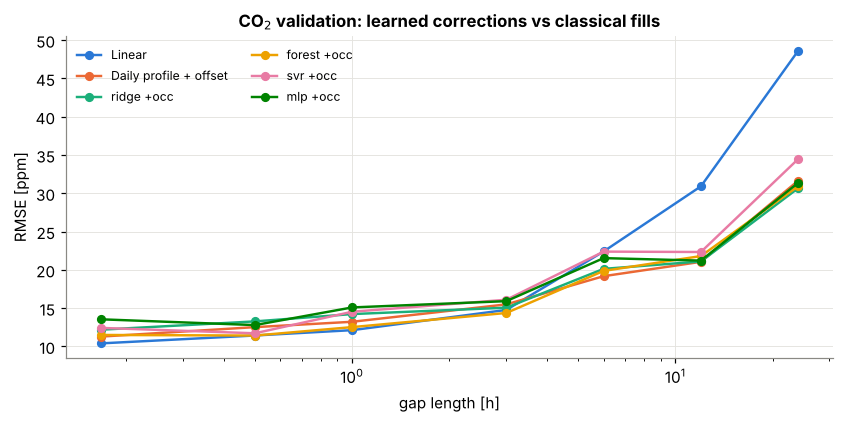

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, name in enumerate(["Linear", "Daily profile + offset", "ridge +occ", "forest +occ", "svr +occ", "mlp +occ"]):
    m = val_res[val_res.method == name].groupby("gap_len").rmse.mean()
    ax.plot(m.index * 10 / 60, m.values, marker="o", color=plotting.PALETTE[i], label=name)
ax.set_xscale("log"); ax.set_xlabel("gap length [h]"); ax.set_ylabel("RMSE [ppm]"); ax.legend(ncol=2, fontsize=8)
ax.set_title("CO$_2$ validation: learned corrections vs classical fills")
_ = plotting.save(fig, "04_val_ml")

## 5. What do the models use? (permutation importance on validation gaps)

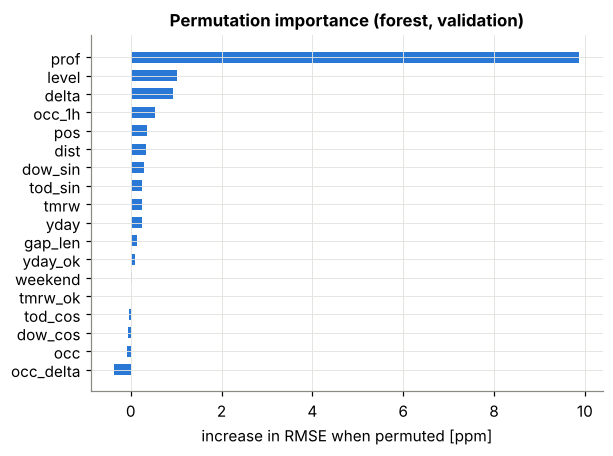

In [9]:
from sensorfill.masking import block_mask, apply_mask
mk = np.zeros(len(y_v), bool)
for L in (18, 72):
    mk |= block_mask(~np.isnan(y_v) & ~mk, L, 10, np.random.default_rng(L), margin=2, min_observed=0.8)
bv = builder(ts_v, occ_v)
Xv, idx, base = bv.build(apply_mask(y_v, mk))
keep = mk[idx]
best_name = "forest"
model = ml.make_model(best_name, **best_params[best_name]).fit(X, r)
pi = permutation_importance(model, Xv[keep], (y_v[idx] - base[idx])[keep], scoring="neg_root_mean_squared_error", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=Xv.columns).sort_values()
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.barh(imp.index, imp.values, color=plotting.PALETTE[0], height=0.6)
ax.set_xlabel("increase in RMSE when permuted [ppm]"); ax.set_title(f"Permutation importance ({best_name}, validation)")
_ = plotting.save(fig, "04_permutation_importance")

### Conclusions (validation)
* **Over-fitting is visible and controlled.** The tree's training error falls to zero with depth, while its CV error is lowest at depth 6. The random forest fits its training folds far more closely (about 5 ppm) than it predicts held-out gaps (about 19 ppm), but averaging over trees still gives the best CV score.
* **Short gaps (up to 1 h).** Plain linear interpolation is best or tied (about 10 ppm at 10 min, against 11–13 ppm for every learned model). The learned corrections add variance where there is little signal to learn. At 3 h the forest is marginally better (14.4 vs 14.8 ppm), within the mask-to-mask variation. This sets the hybrid policy evaluated in notebook 06.
* **Long gaps (6–24 h).** Every learned model and the daily profile reduce the error substantially versus linear interpolation (for example, 24 h: about 31 ppm vs 49 ppm). However, the **learned models are not clearly better than the simple daily profile with offset**: the differences of 1–2 ppm are within the mask-to-mask variation. Permutation importance explains why: the models rely overwhelmingly on the profile feature (`prof`). Neighbouring-day shapes and occupancy contribute little.
* **Occupancy ablation.** Adding the building-occupancy proxy improves 24-h gaps by about 1 ppm for the linear models and changes little otherwise. Because the proxy is not measured in this room, it carries little information beyond the time-of-day pattern that the profile already captures.
* **Learning curve.** Validation error keeps falling up to the full 8.7 weeks for the forest. Ridge regression plateaus after about 6 weeks. Its jump at 2 weeks most likely reflects one unrepresentative fortnight, which a linear model cannot average out. More data would mostly benefit the flexible model.
* **Cost.** Ridge regression trains in about 0.02 s and is fully interpretable. The forest takes about 8 s, the MLP about 20 s, and SVR needed subsampling (O(n²) kernel). SVR and MLP were never better than the forest, and were worse than ridge for long gaps.
* **Caveat (see notebook 06).** These are validation results from the same semester as training. On the calmer test period, the learned corrections' advantage for long gaps did not hold.
* **Carried to the final benchmark:** ridge +occ (cheap and interpretable) and random forest +occ (best CV score), with the tuned hyperparameters in `reports/ml_best_params.json`. The daily profile remains the classical benchmark that they must beat.